# MODIS: long-term condition indices for eastern Austria, and the climate context

**Question:** *Is this summer's vegetation stress unusual in a 25-year perspective, and how far does it
reach beyond the Marchfeld?*

Sentinel-2 and Landsat give field detail but a short record. Condition indices need a long one: the
minimum and maximum of a month over 9 years are not the same as over 25. MODIS on NASA's Terra satellite
has observed daily since 2000, at 250 m–1 km. Here we build monthly MODIS composites for Vienna, Lower
Austria and Burgenland and compute:

* **VCI** from NDVI (MOD13A1, 500 m, 16-day),
* **TCI** from daytime land-surface temperature (MOD11A2, 1 km, 8-day),
* **VHI** = ½ (VCI + TCI),

against a 2001–2020 baseline, then compare the Marchfeld's VHI with ERA5 **SPI** and **SPEI**, the
standard climate-side indices.

In [1]:
import sys
import warnings
from pathlib import Path

# make the course helper package importable from any sub-folder
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "droughtkit").is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

import droughtkit as dk
from droughtkit import plotting as dkp

dkp.use_style()
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.float_format", "{:.2f}".format)

In [2]:
from droughtkit import maps as dkm
from droughtkit import remote_sensing as rs
from droughtkit import sample as sm

REGION = dk.EAST_AUSTRIA_BBOX       # lon/lat
YEARS = range(2001, 2027)
MONTHS = (4, 5, 6, 7, 8, 9)
BASELINE = (2001, 2020)
TARGET = "2026-07-01"
RUN_STAC = True

cache = ROOT / "data" / "modis_east_austria_monthly.nc"
modis = None
if cache.exists():
    modis = xr.open_dataset(cache).load()
elif RUN_STAC:
    try:
        catalog = rs.open_catalog()
        kw = dict(catalog=catalog, crs="EPSG:3416", months=MONTHS)
        nd = rs.load_modis_ndvi(REGION, "2001-01-01", "2026-10-31", product="13A1", **kw)
        lst = rs.load_modis_lst(REGION, "2001-01-01", "2026-10-31", **kw)
        # monthly medians; LST is aggregated to the NDVI grid (1 km -> 500 m nearest)
        nd_m = rs.monthly_composite(nd, MONTHS).compute()
        lst_m = rs.monthly_composite(lst, MONTHS).compute().interp_like(nd_m, method="nearest")
        modis = xr.Dataset({"ndvi": nd_m, "lst": lst_m}).drop_vars("spatial_ref", errors="ignore")
        modis.attrs["source"] = "NASA MOD13A1 / MOD11A2 v061 via Microsoft Planetary Computer"
        modis.to_netcdf(cache)
    except Exception as exc:
        print(f"Planetary Computer not reachable ({type(exc).__name__}); using the synthetic stand-in.")
if modis is None:
    modis = sm.sample_modis(YEARS, MONTHS)
SRC = modis.attrs["source"]
print(SRC)

Planetary Computer not reachable (APIError); using the synthetic stand-in.


MODIS-like synthetic sample (not real observations)


> The first online run reads ~25 years of MODIS tiles for eastern Austria (two tiles, about 300 NDVI and
> 600 LST granules for April–September) and can take 20–40 minutes; the result is cached. The stored outputs
> come from the offline synthetic stand-in, which mimics eastern Austria's pattern of forested hills in the
> west and arable lowlands in the east.

## VCI, TCI and VHI maps

All three use the same logic: where does this month sit between the lowest and highest value of the same
calendar month in 2001–2020?

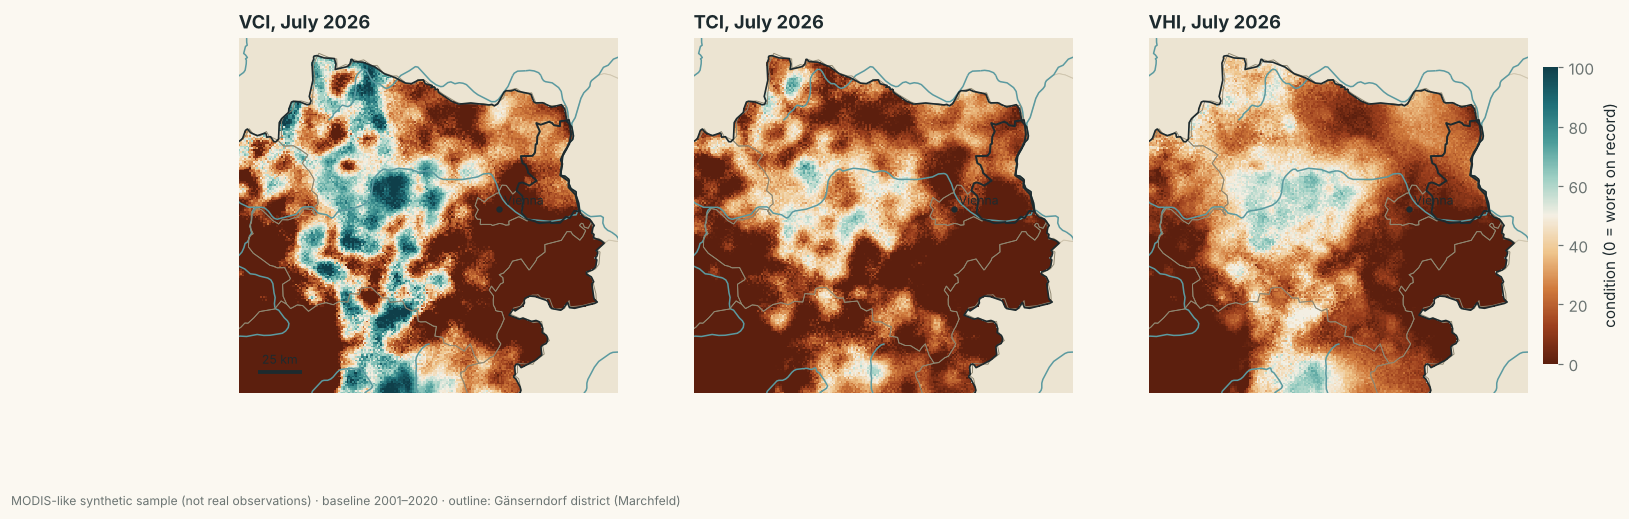

In [3]:
vci = dk.vci(modis.ndvi, BASELINE)
tci = dk.tci(modis.lst, BASELINE)
vhi = dk.vhi(vci, tci)

gx = dkm.layer("austria_districts").query("name == 'Gänserndorf'").to_crs(dkm.AT_CRS)
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, (name, da) in zip(ax, [("VCI", vci), ("TCI", tci), ("VHI", vhi)]):
    d = da.sel(time=TARGET)
    m = a.pcolormesh(d.x, d.y, d, cmap=dkp.DRY_WET, vmin=0, vmax=100, shading="nearest", rasterized=True)
    dkm.context(a, extent=REGION, places=5, neighbours=True, fill_austria=False)
    gx.boundary.plot(ax=a, color=dkp.INK, lw=1.3, zorder=7)
    a.set_title(f"{name}, {pd.Timestamp(TARGET):%B %Y}"); a.set_xlabel(""); a.set_ylabel("")
cb = fig.colorbar(m, ax=ax, shrink=0.7, pad=0.01); cb.set_label("condition (0 = worst on record)")
cb.outline.set_visible(False)
dkm.scalebar(ax[0], 25)
dkp.source_note(fig, f"{SRC} · baseline {BASELINE[0]}–{BASELINE[1]} · outline: Gänserndorf district (Marchfeld)")

**Reading the maps.** VCI reacts to the cumulative effect on vegetation; TCI reacts within days to heat and
lost evaporative cooling. Forested hills often show a TCI signal before any VCI signal. Arable lowlands
show both, unless irrigation keeps them cool and green.

## One map per year: how unusual is July 2026?

Small multiples of July VHI put the current season next to earlier droughts such as 2003, 2015 and 2018.

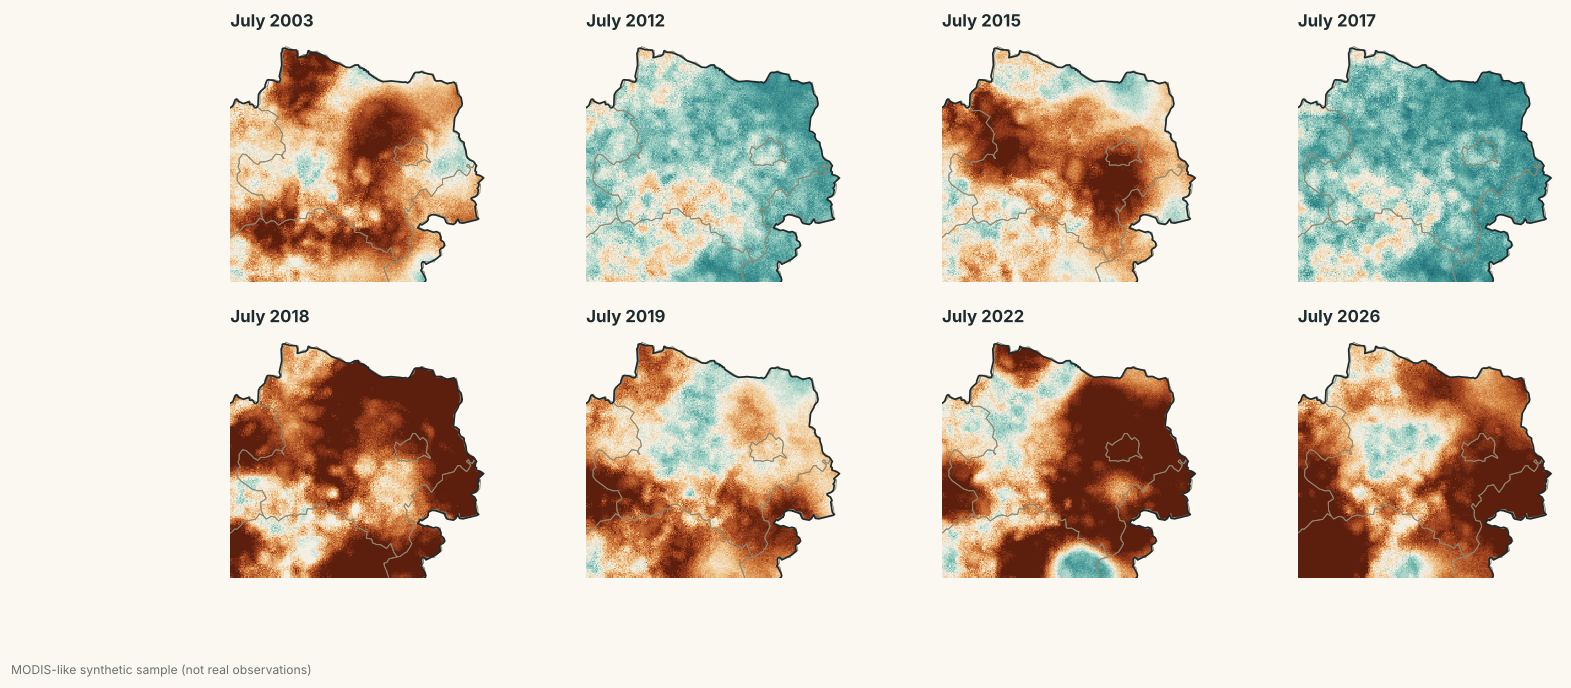

In [4]:
july = vhi.sel(time=vhi.time.dt.month == 7)
show = [y for y in [2003, 2012, 2015, 2017, 2018, 2019, 2022, 2026] if y in july.time.dt.year]
fig, ax = plt.subplots(2, 4, figsize=(16, 6.4))
for a, y in zip(ax.ravel(), show):
    d = july.sel(time=f"{y}-07-01")
    a.pcolormesh(d.x, d.y, d, cmap=dkp.DRY_WET, vmin=0, vmax=100, shading="nearest", rasterized=True)
    dkm.context(a, extent=REGION, places=0, neighbours=False, fill_austria=False, rivers=False)
    a.set_title(f"July {y}", fontsize=11)
for a in ax.ravel()[len(show):]:
    a.axis("off")
dkp.source_note(fig, SRC)

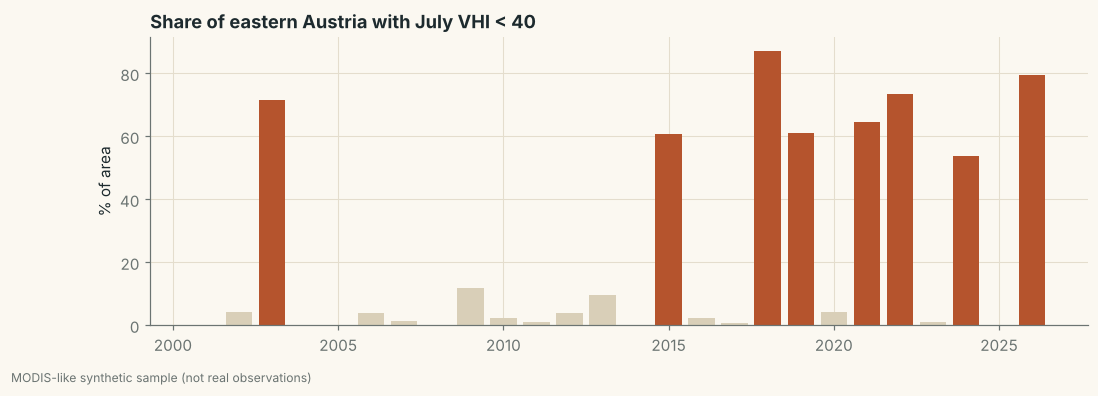

In [5]:
inside = vhi.notnull().any("time")
share = dk.area_below(vhi.where(inside), 40)
jul = share[share.index.month == 7]
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.bar(jul.index.year, jul, color=[dkp.DRY if v > 30 else "#d9cfb8" for v in jul])
ax.set(ylabel="% of area", title="Share of eastern Austria with July VHI < 40")
dkp.source_note(fig, SRC)

## The Marchfeld through the seasons

Averaging VHI over the Gänserndorf district (which contains most of the Marchfeld) gives a monthly series
that can be read alongside weather data.

,months
VHI,
extreme,10
severe,3
moderate,4
mild,10
no drought,129


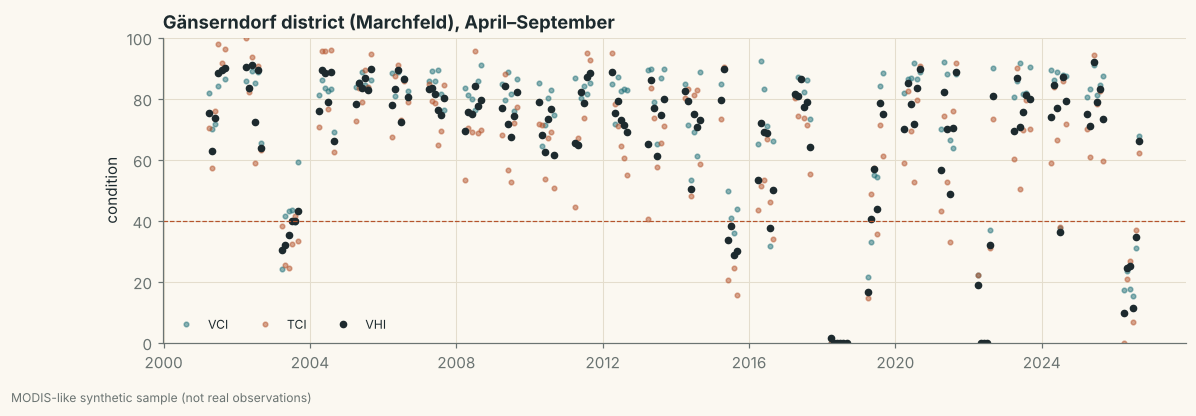

In [6]:
from shapely import contains_xy
X, Y = np.meshgrid(modis.x, modis.y)
in_gx = xr.DataArray(contains_xy(gx.geometry.iloc[0], X, Y), coords={"y": modis.y, "x": modis.x}, dims=("y", "x"))
vhi_mf = vhi.where(in_gx).median(["x", "y"]).to_series()
vci_mf = vci.where(in_gx).median(["x", "y"]).to_series()
tci_mf = tci.where(in_gx).median(["x", "y"]).to_series()

fig, ax = plt.subplots(figsize=(12, 3.6))
for s, name, c in [(vci_mf, "VCI", dkp.WET), (tci_mf, "TCI", dkp.DRY)]:
    ax.plot(s.index, s, ".", color=c, alpha=0.5, label=name)
ax.plot(vhi_mf.index, vhi_mf, "o", color=dkp.INK, ms=4, label="VHI")
ax.axhline(40, color=dkp.DRY, ls="--", lw=0.8)
ax.set(ylim=(0, 100), title="Gänserndorf district (Marchfeld), April–September", ylabel="condition")
ax.legend(ncol=3, fontsize=8)
dkp.source_note(fig, SRC)
dk.classify_vhi(vhi_mf).value_counts(sort=False).to_frame("months")

## Climate context: SPI and SPEI from ERA5

Satellites show the **effect** of drought; climate indices show the **cause**. The Standardized
Precipitation Index (SPI, McKee et al. 1993) expresses accumulated rainfall as a standard-normal value for
that calendar month; the Standardized Precipitation-Evapotranspiration Index (SPEI, Vicente-Serrano et al.
2010) does the same for rainfall minus reference evapotranspiration, so heat counts too. Values below −1 are
moderately dry, below −1.5 severely, below −2 extremely dry.

ERA5 for the Marchfeld comes from the free Open-Meteo archive API (cached after the first call).

Open-Meteo request failed: <urlopen error Tunnel connection failed: 403 Forbidden>
-> falling back to the offline synthetic sample.


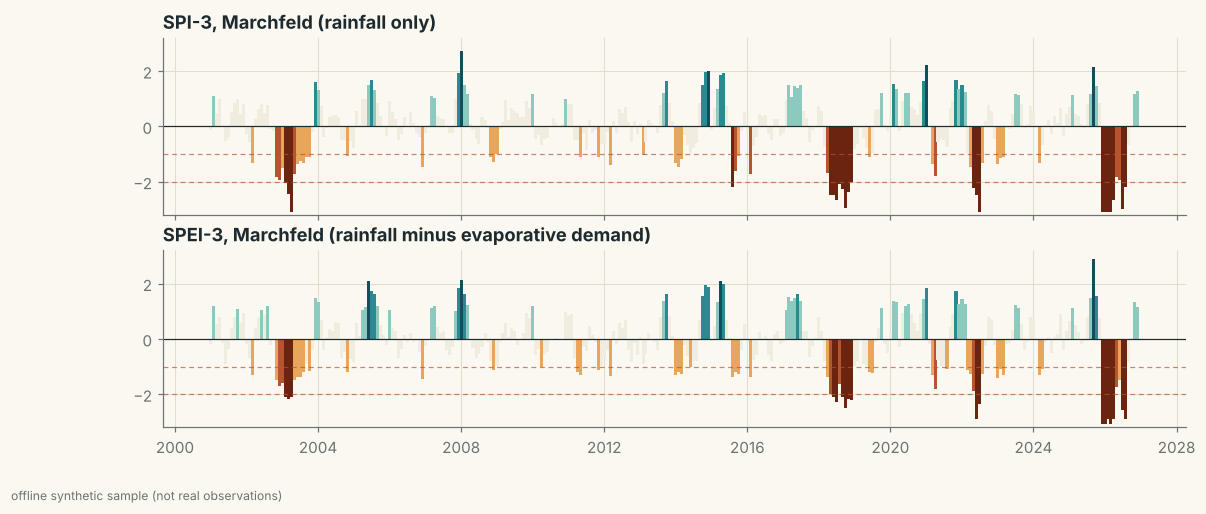

In [7]:
clim = dk.load_climate(cache_dir=ROOT / "data")
spi3 = dk.spi(clim.precip_mm, 3, calibration=(1991, 2020))
spei3 = dk.spei(clim.precip_mm, clim.et0_mm, 3, calibration=(1991, 2020))

fig, ax = plt.subplots(2, 1, figsize=(12, 4.6), sharex=True)
dkp.index_bars(spi3["2001":], ax[0], title="SPI-3, Marchfeld (rainfall only)")
dkp.index_bars(spei3["2001":], ax[1], title="SPEI-3, Marchfeld (rainfall minus evaporative demand)")
for a in ax:
    a.set_yticks([-2, 0, 2])
dkp.source_note(fig, clim.attrs["source"])

Does vegetation follow the water balance? Correlating the growing-season VHI with SPEI at different
accumulation scales shows which time window the Marchfeld's vegetation integrates over.

,r with VHI
SPEI-1,0.75
SPEI-2,0.76
SPEI-3,0.75
SPEI-6,0.68
SPEI-12,0.47


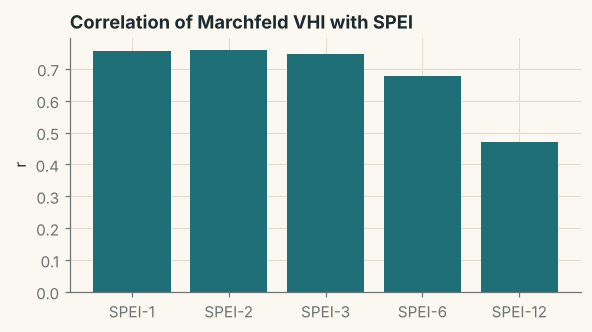

In [8]:
rows = {}
for k in (1, 2, 3, 6, 12):
    s = dk.spei(clim.precip_mm, clim.et0_mm, k, calibration=(1991, 2020))
    both = pd.concat([vhi_mf, s], axis=1, join="inner").dropna()
    rows[f"SPEI-{k}"] = both.corr().iloc[0, 1]
r = pd.Series(rows, name="r with VHI")
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(r.index, r, color=dkp.WET)
ax.set(title="Correlation of Marchfeld VHI with SPEI", ylabel="r")
r.to_frame()

## Exercises

1. Replace `TARGET` with July 2018 and July 2022. Is the spatial pattern of stress the same in every drought?
2. Compute VHI with α = 0.3 and 0.7. Where do forested and arable areas react differently?
3. Use `product="13Q1"` (250 m) for the Gänserndorf district only. What detail appears?
4. Repeat the correlation with SPI instead of SPEI. What does the difference say about heat?
5. Compare the MODIS VCI for the Marchfeld with the Sentinel-2 VCI from notebook 2 for the overlapping
   years. Where do they agree, and why might they not?

## Further reading and tools

Ideas in this course were inspired by several open projects; none is required to run it. See the
*Inspiration and further tools* section on the course home page.